<a href="https://colab.research.google.com/github/seungah-lab/PEACHstudy/blob/main/261115_tropical_puberty10_PSKC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Load PSKC, MOCEH dataset

In [2]:
from google.colab import drive
import pandas as pd
import os

drive.mount('/content/drive')

file_path = "/content/drive/MyDrive/2 Grant/W_2022_중견연구_여아 이른 사춘기/한국아동패널/Data/p0823_growth.pkl"

# Load the dataset and save as variable p
try:
    p = pd.read_pickle(file_path)
    print("Dataset loaded successfully as variable 'p'.")
    print(p.head())
except Exception as e:
    print(f"Error loading file: {e}")
    print("Please check if Google Drive is mounted and the file path is correct.")

Mounted at /content/drive
Dataset loaded successfully as variable 'p'.
       N_ID  EMt08dmg006  BMt08pnb001  BCh08dmg006  BCh08dmg006a  BCh08dmg001  \
0  101001.0         31.0        285.0          7.0           5.0          2.0   
1  101002.0         26.0        271.0          5.0           4.0          2.0   
2  101003.0         32.0        283.0          5.0           4.0          1.0   
3  101004.0         34.0        287.0          5.0           4.0          2.0   
4  101005.0         29.0        264.0          5.0           4.0          1.0   

   BCh08hlt001  BCh08hlt002  BCh08hlt003  BCh08dmg002  ...  b9_screen_min  \
0          3.7   99999999.0   99999999.0          1.0  ...           30.0   
1          2.1         41.0   99999999.0          1.0  ...           90.0   
2          3.5   99999999.0   99999999.0          3.0  ...           90.0   
3          3.7         52.0         34.5          1.0  ...            NaN   
4          3.5   99999999.0   99999999.0          2.0  ..

In [ ]:
var_list = p.columns.tolist()
cols_count = 5  # 한 줄에 표시할 변수 개수

# 각 변수의 최대 길이에 맞춰 간격 조정
max_len = max(len(var) for var in var_list) + 3

for i in range(0, len(var_list), cols_count):
    row = var_list[i:i+cols_count]
    print("".join(var.ljust(max_len) for var in row))

In [7]:
# DHu08cmm014 (17시도), DHu08cmm015 (시군구)
print(p['DHu08cmm014'].value_counts(dropna=False))
print(p['DHu08cmm015'].value_counts(dropna=False))

DHu08cmm014
8.0     622
1.0     334
3.0     151
2.0     137
13.0    129
15.0    110
11.0    107
7.0     105
12.0     96
6.0      78
5.0      70
10.0     67
4.0      61
14.0     52
9.0      30
NaN       1
Name: count, dtype: int64
DHu08cmm015
서울특별시/송파구     81
대구광역시/달서구     69
전라남도/순천시      65
부산광역시/해운대구    62
경기도/이천시       58
              ..
전라북도/고창군       1
충청남도/태안군       1
전라남도/여수시       1
전라남도/구례군       1
경상남도/마산시       1
Name: count, Length: 197, dtype: int64


In [8]:
# Convert 'DHu08cmm014' column to character (string) type
p['DHu08cmm014'] = p['DHu08cmm014'].astype(str)

# Display the updated data type and head of the column to verify
print(p['DHu08cmm014'].dtypes)
print(p['DHu08cmm014'].head())

object
0    1.0
1    1.0
2    8.0
3    1.0
4    1.0
Name: DHu08cmm014, dtype: object


In [9]:
# Air pollution data path mapping
ap_file_path = "/content/drive/MyDrive/1 Research/W_학위논문/2023_2026/장호열/GAM_AP_1522_시군구별평균/GAM_AP_1522_행정동별평균.csv"

# Load the dataset
try:
    air = pd.read_csv(ap_file_path)
    print("Air pollution dataset loaded successfully as 'air'.")

Air pollution dataset loaded successfully as 'ap_data'.
Error loading file: name 'ap_data' is not defined


In [10]:
    print(f"Data Shape: {air.shape}")
    display(air.head())

Data Shape: (721734, 10)


,date,sgg_h,PM2_5,gam_PM2_5,O3_8H,gam_O3_8H,O3_24H,gam_O3_24H,NO2,gam_NO2
0,2015-01-01,11010,8.565217,11.807565,0.020750,0.024515,0.018250,0.020246,0.010333,0.011138
1,2015-01-01,11020,10.958330,10.124187,0.023750,0.023261,0.021208,0.019380,0.011417,0.011140
2,2015-01-01,11030,15.416670,13.838317,0.019750,0.022109,0.017500,0.018528,0.012542,0.011804
3,2015-01-01,11040,20.541670,12.969829,0.023250,0.023135,0.020583,0.018992,0.011042,0.011438
4,2015-01-01,11050,8.708333,12.913342,0.021875,0.023156,0.019667,0.018720,0.008500,0.012193


In [11]:
print(p['BCh08dmg006a'].value_counts(dropna=False))  # birth month

BCh08dmg006a
5.0    758
6.0    633
4.0    528
7.0    231
Name: count, dtype: int64


In [17]:
import pandas as pd

# We assume the birth year is 2008.
# Convert 'BCh08dmg006a' to an integer period (Year-Month)
base_period = p['BCh08dmg006a'].dropna().astype(int).apply(lambda m: pd.Period(year=2008, month=m, freq='M'))

# Create the columns by shifting periods and formatting as 'YYYY-MM'
p['month0'] = base_period.apply(lambda p: p.strftime('%Y-%m'))
p['month6'] = (base_period + 6).apply(lambda p: p.strftime('%Y-%m') if pd.notnull(p) else None)
p['month12'] = (base_period + 12).apply(lambda p: p.strftime('%Y-%m') if pd.notnull(p) else None)
p['month24'] = (base_period + 24).apply(lambda p: p.strftime('%Y-%m') if pd.notnull(p) else None)
p['month60'] = (base_period + 60).apply(lambda p: p.strftime('%Y-%m') if pd.notnull(p) else None)

# Display the updated columns to verify
print(p[['month0', 'month6', 'month12', 'month24', 'month60']].head())

    month0   month6  month12  month24  month60
0  2008-05  2008-11  2009-05  2010-05  2013-05
1  2008-04  2008-10  2009-04  2010-04  2013-04
2  2008-04  2008-10  2009-04  2010-04  2013-04
3  2008-04  2008-10  2009-04  2010-04  2013-04
4  2008-04  2008-10  2009-04  2010-04  2013-04


In [16]:
var_list = p.columns.tolist()
cols_count = 5  # 한 줄에 표시할 변수 개수

# 각 변수의 최대 길이에 맞춰 간격 조정
max_len = max(len(var) for var in var_list) + 3

for i in range(0, len(var_list), cols_count):
    row = var_list[i:i+cols_count]
    print("".join(var.ljust(max_len) for var in row))

N_ID              EMt08dmg006       BMt08pnb001       BCh08dmg006       BCh08dmg006a      
BCh08dmg001       BCh08hlt001       BCh08hlt002       BCh08hlt003       BCh08dmg002       
BMt08pnb002       BMt08pnb003       BMt08hlt013       BMt08hlt012       BMt08hlt001       
ECh08hlt012       ECh08hlt013       ECh08hlt014       EMt08drn001       EMt08smk001       
EMt08jcg002       EMt08dmg014       FFt08drn001       FFt08smk001       FFt08jcg002       
FFt08dmg014       DCh08fed001       DCh08fed002       DHu08cmm002       ECh09hlt031       
ECh09hlt033       ECh09hlt012       ECh09hlt013       ECh09hlt014       DHu09cmm002       
ECh10slp022       ECh10slp023       ECh10dlc008       ECh10dlc009       ECh10hlt012       
ECh10hlt013       ECh10hlt031       ECh10hlt044       ECh10hlt043       ECh10hlt030       
ECh10hlt035       ECh10hlt037       ECh10hlt039       ECh10hlt041       DHu10cmm002       
DCh11slp022a      DCh11slp022b      DCh11slp023a      DCh11slp023b      DCh11dlc008       

In [20]:
import pandas as pd

# Load the dataset as t
t_path = '/content/Monthly_Sigungu_Tropical_Nights_2008_2023_monthlysum.csv'
t = pd.read_csv(t_path)

# Display basic info and head
print("Dataset Shape:", t.shape)
display(t.head())


Dataset Shape: (48768, 6)


,시군구코드,시도명,시군구명,지점,YearMonth,monthly_tropical_nights
0,11110,서울특별시,종로구,서울,2008-01,0
1,11110,서울특별시,종로구,서울,2008-02,0
2,11110,서울특별시,종로구,서울,2008-03,0
3,11110,서울특별시,종로구,서울,2008-04,0
4,11110,서울특별시,종로구,서울,2008-05,0


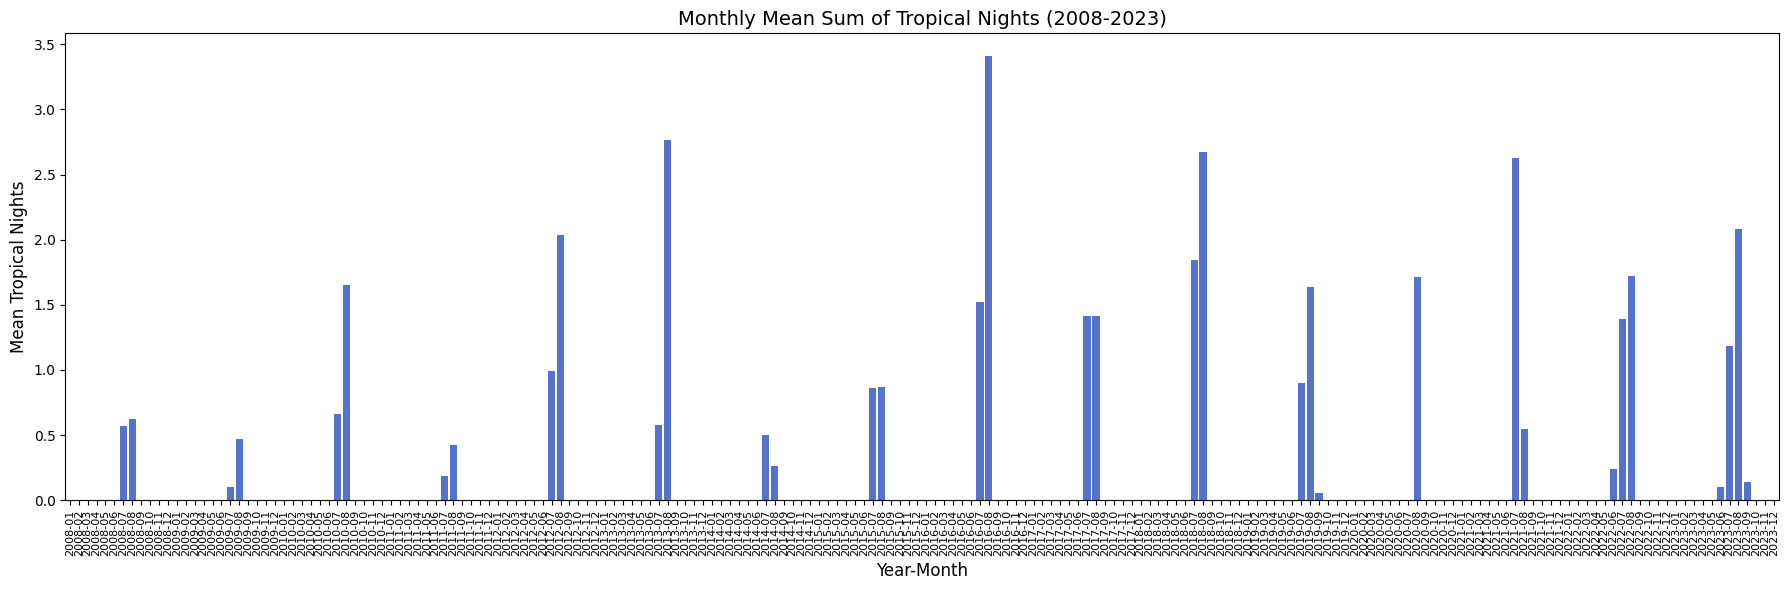

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure YearMonth is sorted chronologically
t = t.sort_values('YearMonth')

# Group by YearMonth and compute the mean sum of tropical nights across all regions
monthly_mean = t.groupby('YearMonth')['monthly_tropical_nights'].mean().reset_index()

# Plot the bar chart
plt.figure(figsize=(18, 6))
sns.barplot(data=monthly_mean, x='YearMonth', y='monthly_tropical_nights', color='royalblue')

# Rotate x-ticks for legibility and adjust layout
plt.xticks(rotation=90, fontsize=8)
plt.title('Monthly Mean Sum of Tropical Nights (2008-2023)', fontsize=14)
plt.xlabel('Year-Month', fontsize=12)
plt.ylabel('Mean Tropical Nights', fontsize=12)
plt.tight_layout()
plt.show()

In [23]:
import pandas as pd
import numpy as np

# 1. Create a reference mapping DataFrame from t
# We take the first 2 characters of '시도명' and '시군구명' to match the logic of the prompt.
ref_df = t[['시도명', '시군구명', '시군구코드']].drop_duplicates().copy()
ref_df['si_key'] = ref_df['시도명'].astype(str).str[:2]
ref_df['gungu_key'] = ref_df['시군구명'].astype(str).str[:2]

# Keep one unique mapping for each (si_key, gungu_key) combination to avoid duplicates during merge
ref_mapping = ref_df.drop_duplicates(subset=['si_key', 'gungu_key']).set_index(['si_key', 'gungu_key'])['시군구코드'].to_dict()

# 2. Extract keys from p for matching
# 'DHu08cmm015' has format like '서울특별시/송파구', '대구광역시/달서구', etc.
# Let's extract the si and gungu part (first 2 letters of each) from 'DHu08cmm015'.
def extract_keys(val):
    if pd.isna(val) or '/' not in str(val):
        return None, None
    parts = str(val).split('/')
    si_part = parts[0].strip()[:2]
    gungu_part = parts[1].strip()[:2]
    return si_part, gungu_part

p_keys = p['DHu08cmm015'].apply(extract_keys)
p_si = p_keys.apply(lambda x: x[0] if x else None)
p_gungu = p_keys.apply(lambda x: x[1] if x else None)

# 3. Map to '시군구코드'
# Using zip to look up combinations in our reference mapping dict
p['시군구코드'] = [ref_mapping.get((s, g), np.nan) for s, g in zip(p_si, p_gungu)]

# 4. Show summary to verify results
print("Mapping completed.")
print(p[['DHu08cmm014', 'DHu08cmm015', '시군구코드']].head(10))
print(f"\nNumber of missing '시군구코드' in p: {p['시군구코드'].isna().sum()}")


Mapping completed.
  DHu08cmm014 DHu08cmm015    시군구코드
0         1.0   서울특별시/성동구  11200.0
1         1.0   서울특별시/광진구  11215.0
2         8.0    경기도/남양주시  41360.0
3         1.0   서울특별시/광진구  11215.0
4         1.0   서울특별시/광진구  11215.0
5         1.0  서울특별시/동대문구  11230.0
6         8.0     경기도/하남시  41450.0
7         1.0   서울특별시/성동구  11200.0
8         1.0   서울특별시/성동구  11200.0
9         1.0   서울특별시/성동구  11200.0

Number of missing '시군구코드' in p: 24


/tmp/ipykernel_2749/1509831704.py:30: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  p['시군구코드'] = [ref_mapping.get((s, g), np.nan) for s, g in zip(p_si, p_gungu)]


In [24]:
print(p['시군구코드'].value_counts(dropna=False))

시군구코드
41281.0    99
41111.0    98
11710.0    81
41465.0    78
27290.0    69
           ..
45180.0     1
45790.0     1
44825.0     1
46130.0     1
46730.0     1
Name: count, Length: 172, dtype: int64


In [25]:
import pandas as pd
import numpy as np

# Ensure YearMonth is string type and formatted properly in t
t['YearMonth'] = t['YearMonth'].astype(str)

# Create a multi-index Series for quick lookup of (시군구코드, YearMonth) -> monthly_tropical_nights
t_lookup = t.groupby(['시군구코드', 'YearMonth'])['monthly_tropical_nights'].sum()

def get_tropical_nights_sum(sgg_code, start_ym, end_ym):
    if pd.isna(sgg_code) or pd.isna(start_ym) or pd.isna(end_ym):
        return np.nan

    try:
        sgg_code_val = float(sgg_code)
        # Generate a range of months from start_ym to end_ym inclusive
        months = pd.date_range(start=start_ym, end=end_ym, freq='MS').strftime('%Y-%m').tolist()

        # Retrieve values from the lookup table for the specific sgg_code and months
        total_sum = 0.0
        for m in months:
            val = t_lookup.get((sgg_code_val, m), 0.0)
            total_sum += val
        return total_sum
    except Exception:
        return np.nan

# Calculate each variable based on the respective timeframe boundaries
p['tropical_6mo'] = p.apply(
    lambda r: get_tropical_nights_sum(r['시군구코드'], r['month0'], r['month6']), axis=1
)

p['tropical_24mo'] = p.apply(
    lambda r: get_tropical_nights_sum(r['시군구코드'], r['month6'], r['month24']), axis=1
)

p['tropical_60mo'] = p.apply(
    lambda r: get_tropical_nights_sum(r['시군구코드'], r['month24'], r['month60']), axis=1
)

# Display summary statistics
display(p[['month0', 'month6', 'month24', 'month60', '시군구코드', 'tropical_6mo', 'tropical_24mo', 'tropical_60mo']].head())
print("Summary of newly created variables:")
display(p[['tropical_6mo', 'tropical_24mo', 'tropical_60mo']].describe())

/tmp/ipykernel_2749/2498057168.py:29: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  p['tropical_6mo'] = p.apply(
/tmp/ipykernel_2749/2498057168.py:33: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  p['tropical_24mo'] = p.apply(
/tmp/ipykernel_2749/2498057168.py:37: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.

,month0,month6,month24,month60,시군구코드,tropical_6mo,tropical_24mo,tropical_60mo
0,2008-05,2008-11,2010-05,2013-05,11200.0,9.0,4.0,39.0
1,2008-04,2008-10,2010-04,2013-04,11215.0,9.0,4.0,39.0
2,2008-04,2008-10,2010-04,2013-04,41360.0,0.0,0.0,0.0
3,2008-04,2008-10,2010-04,2013-04,11215.0,9.0,4.0,39.0
4,2008-04,2008-10,2010-04,2013-04,11215.0,9.0,4.0,39.0


Summary of newly created variables:


,tropical_6mo,tropical_24mo,tropical_60mo
count,2126.000000,2126.000000,2126.000000
mean,1.835842,1.026341,9.238946
std,3.426520,2.069444,16.521481
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,0.000000,0.000000,5.000000
max,9.000000,9.000000,44.000000


In [26]:
# Calculate growth velocities (gain rate per year)
# Period 1: birth to 6 months (0.5 years)
p['S1_wt'] = (p['b_wt'] - p['birth_wt']) / 0.5
p['S1_ht'] = (p['b_ht'] - p['birth_ht']) / 0.5

# Period 2: 6 months to 24 months (1.5 years)
p['S2_wt'] = (p['b2_wt'] - p['b_wt']) / 1.5
p['S2_ht'] = (p['b2_ht'] - p['b_ht']) / 1.5

# Period 3: 24 months to 60 months (3.0 years)
p['S3_wt'] = (p['b5_wt'] - p['b2_wt']) / 3.0
p['S3_ht'] = (p['b5_ht'] - p['b2_ht']) / 3.0

# Verify and display summary statistics of the newly created variables
print("Growth Velocities Calculated Successfully:")
display(p[['S1_wt', 'S2_wt', 'S3_wt', 'S1_ht', 'S2_ht', 'S3_ht']].describe())

Growth Velocities Calculated Successfully:


/tmp/ipykernel_2749/2614266875.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  p['S1_wt'] = (p['b_wt'] - p['birth_wt']) / 0.5
/tmp/ipykernel_2749/2614266875.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  p['S1_ht'] = (p['b_ht'] - p['birth_ht']) / 0.5
/tmp/ipykernel_2749/2614266875.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragment

,S1_wt,S2_wt,S3_wt,S1_ht,S2_ht,S3_ht
count,1454.000000,1209.000000,1535.000000,1002.000000,792.000000,1247.000000
mean,8.718569,3.300469,2.242150,31.170858,15.356902,7.214969
std,1.747920,0.813074,0.682206,6.974905,2.792170,1.486750
min,2.000000,-1.000000,0.400000,-8.000000,-2.266667,1.333333
25%,7.600000,2.733333,1.833333,27.000000,14.000000,6.333333
50%,8.600000,3.333333,2.166667,30.000000,15.333333,7.166667
75%,9.800000,3.800000,2.533333,36.000000,16.666667,8.000000
max,15.000000,7.133333,6.833333,76.000000,30.666667,13.666667


In [28]:
# Define output path in the same directory as the source file
output_csv_path = "/content/drive/MyDrive/2 Grant/W_2022_중견연구_여아 이른 사춘기/한국아동패널/Data/p0823_growth_updated.csv"

try:
    # Save DataFrame p to CSV
    p.to_csv(output_csv_path, index=False, encoding='utf-8-sig')
    print(f"Successfully saved the updated dataset to: {output_csv_path}")
except Exception as e:
    print(f"Error saving file: {e}")

Successfully saved the updated dataset to: /content/drive/MyDrive/2 Grant/W_2022_중견연구_여아 이른 사춘기/한국아동패널/Data/p0823_growth_updated.csv


In [29]:
print(p['b10_puberty'].value_counts(dropna=False))

b10_puberty
0.0    1337
NaN     716
1.0      97
Name: count, dtype: int64


### S1 -- (tropical_6mo) --> P10

In [36]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.mediation import Mediation
import warnings
import os
import contextlib

# Suppress optimization messages and warnings for cleaner output
warnings.filterwarnings('ignore')

# Prepare the dataset by dropping missing values for analysis variables
analysis_cols = ['tropical_6mo', 'S1_wt', 'b10_puberty', 'BCh08dmg002']
med_data = p[analysis_cols].dropna().copy()
med_data['Sex'] = med_data['BCh08dmg002'].map({1.0: 'Boy', 2.0: 'Girl'})

print("Sample Size by Sex:")
print(med_data['Sex'].value_counts())

for sex_category in ['Girl', 'Boy']:
    df_subset = med_data[med_data['Sex'] == sex_category]
    if len(df_subset) < 20:
        print(f"\nNot enough observations to run mediation for {sex_category}.")
        continue

    print(f"\n=== Causal Mediation Analysis for {sex_category} (N={len(df_subset)}) ===")

    # Mediator model (OLS: S1_wt continuous)
    mediator_model = smf.ols('S1_wt ~ tropical_6mo', data=df_subset)

    # Outcome model (Logit: b10_puberty is binary 0/1)
    outcome_model = smf.logit('b10_puberty ~ tropical_6mo + S1_wt', data=df_subset)

    # Run Mediation Analysis while suppressing logit iteration logs
    med = Mediation(outcome_model, mediator_model, exposure='tropical_6mo', mediator='S1_wt')
    with open(os.devnull, 'w') as devnull:
        with contextlib.redirect_stdout(devnull):
            med_result = med.fit(method='bootstrap', n_rep=500)

    # Display Results
    print(med_result.summary(alpha=0.05))

Sample Size by Sex:
Sex
Boy     463
Girl    400
Name: count, dtype: int64

=== Causal Mediation Analysis for Girl (N=400) ===
                          Estimate  Lower CI bound  Upper CI bound  P-value
ACME (control)            0.000217       -0.003689        0.004233    0.880
ACME (treated)            0.000223       -0.003658        0.004295    0.880
ADE (control)             0.001697       -0.006788        0.006894    0.500
ADE (treated)             0.001703       -0.006684        0.007038    0.500
Total effect              0.001920       -0.007993        0.008016    0.480
Prop. mediated (control)  0.092591       -4.529810        3.219755    0.704
Prop. mediated (treated)  0.097180       -4.545154        3.304608    0.704
ACME (average)            0.000220       -0.003690        0.004269    0.880
ADE (average)             0.001700       -0.006736        0.006910    0.500
Prop. mediated (average)  0.096555       -4.537482        3.262181    0.704

=== Causal Mediation Analysis for Boy

### S2 --(tropical_24mo)--> P10

In [38]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.mediation import Mediation
import warnings
import os
import contextlib

# Suppress optimization messages and warnings for cleaner output
warnings.filterwarnings('ignore')

# Prepare the dataset by dropping missing values for analysis variables
analysis_cols = ['tropical_24mo', 'S2_wt', 'b10_puberty', 'BCh08dmg002']
med_data = p[analysis_cols].dropna().copy()
med_data['Sex'] = med_data['BCh08dmg002'].map({1.0: 'Boy', 2.0: 'Girl'})

print("Sample Size by Sex:")
print(med_data['Sex'].value_counts())

for sex_category in ['Girl', 'Boy']:
    df_subset = med_data[med_data['Sex'] == sex_category]
    if len(df_subset) < 20:
        print(f"\nNot enough observations to run mediation for {sex_category}.")
        continue

    print(f"\n=== Causal Mediation Analysis for {sex_category} (N={len(df_subset)}) ===")

    # Mediator model (OLS: S2_wt continuous)
    mediator_model = smf.ols('S2_wt ~ tropical_24mo', data=df_subset)

    # Outcome model (Logit: b10_puberty is binary 0/1)
    outcome_model = smf.logit('b10_puberty ~ tropical_24mo + S2_wt', data=df_subset)

    # Run Mediation Analysis while suppressing logit iteration logs
    med = Mediation(outcome_model, mediator_model, exposure='tropical_24mo', mediator='S2_wt')
    with open(os.devnull, 'w') as devnull:
        with contextlib.redirect_stdout(devnull):
            med_result = med.fit(method='bootstrap', n_rep=500)

    # Display Results
    print(med_result.summary(alpha=0.05))

Sample Size by Sex:
Sex
Boy     431
Girl    383
Name: count, dtype: int64

=== Causal Mediation Analysis for Girl (N=383) ===
                          Estimate  Lower CI bound  Upper CI bound  P-value
ACME (control)           -0.000697       -0.006054        0.003384    0.784
ACME (treated)           -0.000660       -0.005743        0.003282    0.776
ADE (control)            -0.004143       -0.019588        0.005627    0.568
ADE (treated)            -0.004106       -0.019404        0.005483    0.568
Total effect             -0.004803       -0.022047        0.005331    0.480
Prop. mediated (control)  0.084773       -3.259417        4.107420    0.744
Prop. mediated (treated)  0.075409       -3.215636        4.298830    0.736
ACME (average)           -0.000679       -0.005921        0.003296    0.776
ADE (average)            -0.004125       -0.019406        0.005586    0.568
Prop. mediated (average)  0.079308       -3.237526        4.224537    0.736

=== Causal Mediation Analysis for Boy

### S3--(tropical_60mo)--> P10

In [39]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.mediation import Mediation
import warnings
import os
import contextlib

# Suppress optimization messages and warnings for cleaner output
warnings.filterwarnings('ignore')

# Prepare the dataset by dropping missing values for analysis variables
analysis_cols = ['tropical_60mo', 'S3_wt', 'b10_puberty', 'BCh08dmg002']
med_data = p[analysis_cols].dropna().copy()
med_data['Sex'] = med_data['BCh08dmg002'].map({1.0: 'Boy', 2.0: 'Girl'})

print("Sample Size by Sex:")
print(med_data['Sex'].value_counts())

for sex_category in ['Girl', 'Boy']:
    df_subset = med_data[med_data['Sex'] == sex_category]
    if len(df_subset) < 20:
        print(f"\nNot enough observations to run mediation for {sex_category}.")
        continue

    print(f"\n=== Causal Mediation Analysis for {sex_category} (N={len(df_subset)}) ===")

    # Mediator model (OLS: S1_wt continuous)
    mediator_model = smf.ols('S3_wt ~ tropical_60mo', data=df_subset)

    # Outcome model (Logit: b10_puberty is binary 0/1)
    outcome_model = smf.logit('b10_puberty ~ tropical_60mo + S3_wt', data=df_subset)

    # Run Mediation Analysis while suppressing logit iteration logs
    med = Mediation(outcome_model, mediator_model, exposure='tropical_60mo', mediator='S3_wt')
    with open(os.devnull, 'w') as devnull:
        with contextlib.redirect_stdout(devnull):
            med_result = med.fit(method='bootstrap', n_rep=500)

    # Display Results
    print(med_result.summary(alpha=0.05))

Sample Size by Sex:
Sex
Boy     580
Girl    530
Name: count, dtype: int64

=== Causal Mediation Analysis for Girl (N=530) ===
                          Estimate  Lower CI bound  Upper CI bound  P-value
ACME (control)            0.000036       -0.001801        0.001822    0.948
ACME (treated)            0.000037       -0.001796        0.001797    0.948
ADE (control)             0.000046       -0.001553        0.001098    0.824
ADE (treated)             0.000046       -0.001553        0.001100    0.824
Total effect              0.000083       -0.002288        0.002165    0.864
Prop. mediated (control)  0.342020       -5.960844        4.389841    0.596
Prop. mediated (treated)  0.340999       -5.976276        4.404787    0.596
ACME (average)            0.000036       -0.001799        0.001809    0.948
ADE (average)             0.000046       -0.001557        0.001099    0.824
Prop. mediated (average)  0.342383       -5.968560        4.397314    0.596

=== Causal Mediation Analysis for Boy

### DAG

### Summary of Stratified Causal Mediation Analyses

Below is a summary table containing the Average Causal Mediation Effects (ACME/Indirect effect), Average Direct Effects (ADE), and Total Effects for each analysis step, stratified by sex ($
\alpha = 0.05$):

| Exposure Period & Mediator | Sex | ACME (Average) [95% CI] | ADE (Average) [95% CI] | Total Effect [95% CI] |
| :--- | :--- | :--- | :--- | :--- |
| **S1 (0-6 months)**<br>Exposure: `tropical_6mo`<br>Mediator: `S1_wt` | **Girl** | 0.000220 [-0.003690, 0.004269]<br>(p = 0.880) | 0.001700 [-0.006736, 0.006910]<br>(p = 0.500) | 0.001920 [-0.007993, 0.008016]<br>(p = 0.480) |
| | **Boy** | 0.000139 [-0.001194, 0.001699]<br>(p = 0.900) | 0.002744 [-0.003544, 0.006966]<br>(p = 0.268) | 0.002883 [-0.003692, 0.007543]<br>(p = 0.276) |
| **S2 (6-24 months)**<br>Exposure: `tropical_24mo`<br>Mediator: `S2_wt` | **Girl** | -0.000679 [-0.005921, 0.003296]<br>(p = 0.776) | -0.004125 [-0.019406, 0.005586]<br>(p = 0.568) | -0.004803 [-0.022047, 0.005331]<br>(p = 0.480) |
| | **Boy** | -0.000044 [-0.002476, 0.002707]<br>(p = 0.956) | 0.000546 [-0.011015, 0.008600]<br>(p = 0.776) | 0.000502 [-0.010711, 0.008812]<br>(p = 0.800) |
| **S3 (24-60 months)**<br>Exposure: `tropical_60mo`<br>Mediator: `S3_wt` | **Girl** | 0.000036 [-0.001799, 0.001809]<br>(p = 0.948) | 0.000046 [-0.001557, 0.001099]<br>(p = 0.824) | 0.000083 [-0.002288, 0.002165]<br>(p = 0.864) |
| | **Boy** | 0.000031 [-0.001174, 0.001340]<br>(p = 0.992) | 0.000451 [-0.000610, 0.001244]<br>(p = 0.376) | 0.000482 [-0.001175, 0.001986]<br>(p = 0.476) |

*Note: None of the direct, indirect (mediation), or total effects reached statistical significance (p > 0.05) in any model.*

### Causal Mediation DAG (Conceptual Overview)

The causal pathway maps exposure (Tropical Nights) to later Puberty Outcomes (`b10_puberty`) at age 10, mediated through Weight Growth Velocity (S1, S2, or S3):

```mermaid
graph LR
    %% Nodes
    A(Tropical Nights Exposure<br>tropical_6mo / 24mo / 60mo) -->|Indirect Effect: ACME| B(Weight Growth Velocity<br>S1_wt / S2_wt / S3_wt)
    B --> B1(Puberty at 10 Years<br>b10_puberty)
    A -->|Direct Effect: ADE| B1

    %% Styles
    style A fill:#f9f,stroke:#333,stroke-width:1px
    style B fill:#bbf,stroke:#333,stroke-width:1px
    style B1 fill:#bfb,stroke:#333,stroke-width:1px
```